# Federal Drug Offenses Analysis (2025)

## Project Overview
This project focuses on extracting, cleaning, and analyzing federal criminal records to uncover key trends in criminal justice data. Using raw sentencing files from the United States Sentencing Commission (USSC), the objective was to engineer an optimized data pipeline to handle an overwhelming dataset, isolate a specific analytical scope, and visualize the findings.

## Project Lifecycle & Methodology

1. **Database Discovery & Retrieval**
   * Targeted public sentencing frameworks and acquired raw, research-grade files directly from the United States Sentencing Commission (USSC) records. Constantly utilizing the USSC codebook to determine what frameworks to focus on and codes to reference.

2. **Data Wrangling & Scope Refinement**
   * Navigated an initial "data swamp" featuring an immense volume of information spanning over 22,000 individual column headers. 
   * Programmatically filtered and reduced the dataset down to core demographic variables, offense identifiers, and specific drug tracking metrics (`DRUGTYP`).

3. **Memory-Safe Pipeline Engineering**
   * Because the raw file size consistently freezes and crashes standard tools like Microsoft Excel, I constructed a custom Python streaming pipeline.
   * Utilized `pandas` chunking techniques to safely read, process, and clean the rows in consistent 10,000-row intervals without overwhelming system RAM.

4. **Targeted Analytical Focus (2025 Metrics)**
   * Isolated the core dataset exclusively to cases involving active drug charges (filtering where `NODRUG >= 1`).
   * Aggregated, stacked, and flattened multiple parallel drug classification columns to isolate the **Top 10 Most Frequent Federal Drug Offenses** for the year 2025.

5. **Tool Modernization & Dashboarding (Side Project)**
   * Exported the final, highly optimized subset into a lightweight CSV file.
   * Loaded the cleaned data into Tableau to explore its interface, design layout mechanics, and build a vertical data presentation showcasing the final leaderboard.

## Key Insights
* As a person who does not know a lot about the different drugs, it was interesting to find out "Fentanyl n-phenyl" was the number 1 drug found in most of the offenses for this dataset

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import csv

Due to original csv file size being too large for github I will be creating a smaller csv file based around the drug data.

I will comment out the steps I took to make the csv file smaller

First I wanted to look at the number of columns in the original csv "opafy25nid.csv" which totaled out to 22149 columns

In [20]:
"""
file_path = "opafy25nid.csv"

# Reading the raw CSV file to inspect its total number of columns
with open(file_path, "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader) 

print(f"Total Columns: {len(header)}")
# Total Columns: 22149
"""

'\nfile_path = "opafy25nid.csv"\n\n# Reading the raw CSV file to inspect its total number of columns\nwith open(file_path, "r", encoding="utf-8") as f:\n    reader = csv.reader(f)\n    header = next(reader) \n\nprint(f"Total Columns: {len(header)}")\n# Total Columns: 22149\n'

Next I chose which columns I believe would be best for drug offenses

Once the columns were defined I went through the rows to find the rows that had 1 or more drugs in the Number of drugs column "NODRUG"

The total number of rows that had 1 or more drugs listed in the offense is 17640

In [21]:
"""
# Defined columns in codebook related to drug offenses
id_columns = ["USSCIDN", "MONSEX", "HISPORIG", "MONRACE", "CITIZEN", "DISTRICT", "NODRUG", "DRUGMIN", "DRUGPROB", "COMBDRG2", "SENTTCAP", "STATMIN",
            "DRUGTYP1", "DRUGTYP2", "DRUGTYP3", "DRUGTYP4", "DRUGTYP5", "DRUGTYP6", "DRUGTYP7", "DRUGTYP8", "DRUGTYP9", 
            "DRUGTYP10", "DRUGTYP11", "DRUGTYP12", "DRUGTYP13", "DRUGTYP14", "DRUGTYP15", "DRUGTYP16", "DRUGTYP17",
            "UNIT1", "UNIT2", "UNIT3", "UNIT4", "UNIT5", "UNIT6", "UNIT7", "UNIT8", "UNIT9", 
            "UNIT10", "UNIT11", "UNIT12", 'UNIT13', 'UNIT14', 'UNIT15', 'UNIT16', 'UNIT17', 
            "WGT1", "WGT2", "WGT3", "WGT4", "WGT5", "WGT6", "WGT7", "WGT8", "WGT9", 
            "WGT10", "WGT11", "WGT12", "WGT13", "WGT14", "WGT15", "WGT16", "WGT17"]

clean_chunks = []

# utilizing chunksize to read the massive file in small batches
print("Starting memory-safe file streaming...")
for df_sample in pd.read_csv(
    file_path, usecols=id_columns, chunksize=10000
):
    # keeping rows where NODRUG is 1 or more
    filtered_chunk = df_sample[df_sample["NODRUG"] >= 1]

    # Save to clean_chunks
    clean_chunks.append(filtered_chunk)

# concat clean chunks together into one final DataFrame
df_drugs_clean = pd.concat(clean_chunks, ignore_index=True)

print(f"\nDone! Final filtered dataset has {len(df_drugs_clean)} rows.\n")
# Done! Final filtered dataset has 17640 rows.
"""

'\n# Defined columns in codebook related to drug offenses\nid_columns = ["USSCIDN", "MONSEX", "HISPORIG", "MONRACE", "CITIZEN", "DISTRICT", "NODRUG", "DRUGMIN", "DRUGPROB", "COMBDRG2", "SENTTCAP", "STATMIN",\n            "DRUGTYP1", "DRUGTYP2", "DRUGTYP3", "DRUGTYP4", "DRUGTYP5", "DRUGTYP6", "DRUGTYP7", "DRUGTYP8", "DRUGTYP9", \n            "DRUGTYP10", "DRUGTYP11", "DRUGTYP12", "DRUGTYP13", "DRUGTYP14", "DRUGTYP15", "DRUGTYP16", "DRUGTYP17",\n            "UNIT1", "UNIT2", "UNIT3", "UNIT4", "UNIT5", "UNIT6", "UNIT7", "UNIT8", "UNIT9", \n            "UNIT10", "UNIT11", "UNIT12", \'UNIT13\', \'UNIT14\', \'UNIT15\', \'UNIT16\', \'UNIT17\', \n            "WGT1", "WGT2", "WGT3", "WGT4", "WGT5", "WGT6", "WGT7", "WGT8", "WGT9", \n            "WGT10", "WGT11", "WGT12", "WGT13", "WGT14", "WGT15", "WGT16", "WGT17"]\n\nclean_chunks = []\n\n# utilizing chunksize to read the massive file in small batches\nprint("Starting memory-safe file streaming...")\nfor df_sample in pd.read_csv(\n    file_path,

In [22]:
# Save to a smaller CSV file based around drugs
# df_drugs_clean.to_csv("df_drugs_clean.csv", index=False)

Now the smaller drugs csv file has been setup it can been used as a starting point for future analysis

For this project we are focusing on the top drug offenses of 2025

In [23]:
df_clean = pd.read_csv("df_drugs_clean.csv")

print(f"Rows duplicates: {df_clean.duplicated().sum()}\n")

print(df_clean["NODRUG"].value_counts())

Rows duplicates: 0

NODRUG
1.0     10830
2.0      3558
3.0      1780
4.0       829
5.0       365
6.0       160
7.0        43
8.0        41
9.0        21
10.0        5
11.0        3
14.0        2
17.0        2
13.0        1
Name: count, dtype: int64


In [24]:
print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17640 entries, 0 to 17639
Data columns (total 63 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SENTTCAP   16899 non-null  float64
 1   USSCIDN    17640 non-null  int64  
 2   CITIZEN    17605 non-null  float64
 3   COMBDRG2   17640 non-null  float64
 4   DISTRICT   17640 non-null  int64  
 5   DRUGPROB   14498 non-null  float64
 6   HISPORIG   17640 non-null  int64  
 7   MONRACE    17640 non-null  int64  
 8   MONSEX     17634 non-null  float64
 9   NODRUG     17640 non-null  float64
 10  UNIT1      17640 non-null  float64
 11  UNIT2      6810 non-null   float64
 12  UNIT3      3252 non-null   float64
 13  UNIT4      1472 non-null   float64
 14  UNIT5      643 non-null    float64
 15  UNIT6      278 non-null    float64
 16  UNIT7      118 non-null    float64
 17  UNIT8      75 non-null     float64
 18  UNIT9      34 non-null     float64
 19  UNIT10     13 non-null     float64
 20  UNIT11

Due to the way the columns are setup in the csv file we have to search utilize all the DRUGTYP columns to get a proper count of the top drugs

Melting all the DRUGTYP columns into one column so then we can count the value of all the matching numbers

In [25]:
# Grab all your DRUGTYP columns
all_columns = df_clean.columns.tolist()
drugtyp_columns = [col for col in all_columns if "DRUGTYP" in col.upper()]

# Melt the dataframe to turn all these separate columns into one single vertical column
# We keep USSCIDN so we know which case it belongs to
melted_drugs = pd.melt(
    df_clean, id_vars=["USSCIDN"], value_vars=drugtyp_columns
)

# Filter out any 0s or NaNs
# Codebook only has drug codes between 1 and 161
clean_drug_codes = melted_drugs[
    (melted_drugs["value"] >= 1) & (melted_drugs["value"] <= 161)
]

grand_totals = clean_drug_codes["value"].value_counts()

print("--- MOST FREQUENT DRUG CODES ACROSS ALL OFFENSES ---")
print(grand_totals.head(20))

--- MOST FREQUENT DRUG CODES ACROSS ALL OFFENSES ---
value
107.0    6361
1.0      5960
19.0     4749
6.0      4367
4.0      1840
3.0      1705
2.0      1455
10.0      898
113.0     453
11.0      227
77.0      180
119.0     133
13.0       94
136.0      63
116.0      62
112.0      61
141.0      59
150.0      48
9.0        46
151.0      39
Name: count, dtype: int64


With output of the value counts we can see the top 20 values

I referenced the codebook to find the names of the corresponding code number and made a simple dataframe containing the code number, drug name, and total occurances of the drug

In [26]:
top_20_codes = grand_totals.head(20).reset_index()
top_20_codes.columns = ["Drug_Code", "Total_Occurrences"]

# Dictionary of drug codes to their corresponding names
drug_code_to_name = {
    107.0: "Fentanyl n-phenyl",
    1.0: "Cocaine",
    19.0: "Methamphetamine Actual",
    6.0: "Methamphetamine",
    4.0: "Marijuana",
    3.0: "Heroin",
    2.0: "Crack/CokeBase",
    10.0: "ICE",
    113.0: "Oxycodone (Actual)",
    11.0: "MDMA/Ecstasy",
    77.0: "Other",
    119.0: "Hydrocodone",
    13.0: "Amphetamine",
    136.0: "Dry Psilcybin (mushrooms)",
    116.0: "Codeine",
    112.0: "Morphine",
    141.0: "Psilocybin",
    150.0: "Tetrahydrocannabinol (Organic)",
    9.0: "PCP",
    151.0: "Tetrahydrocannabinol (Synth)"
}

# Map drug codes to their corresponding names
top_20_codes["Drug_Name"] = top_20_codes["Drug_Code"].map(drug_code_to_name)

final_leaderboard = top_20_codes[
    ["Drug_Name", "Drug_Code", "Total_Occurrences"]
]

print("--- FINAL 2025 DRUG OFFENSE LEADERBOARD ---")
print(final_leaderboard)

--- FINAL 2025 DRUG OFFENSE LEADERBOARD ---
                         Drug_Name  Drug_Code  Total_Occurrences
0                Fentanyl n-phenyl      107.0               6361
1                          Cocaine        1.0               5960
2           Methamphetamine Actual       19.0               4749
3                  Methamphetamine        6.0               4367
4                        Marijuana        4.0               1840
5                           Heroin        3.0               1705
6                   Crack/CokeBase        2.0               1455
7                              ICE       10.0                898
8               Oxycodone (Actual)      113.0                453
9                     MDMA/Ecstasy       11.0                227
10                           Other       77.0                180
11                     Hydrocodone      119.0                133
12                     Amphetamine       13.0                 94
13       Dry Psilcybin (mushrooms)      136.0 

In [27]:
# Save to a CSV file for tableau
final_leaderboard.to_csv("ussc_2025_top_20_drugs.csv", index=False)

I made a simple bargraph using matplot library and the final_leaderboard dataframe

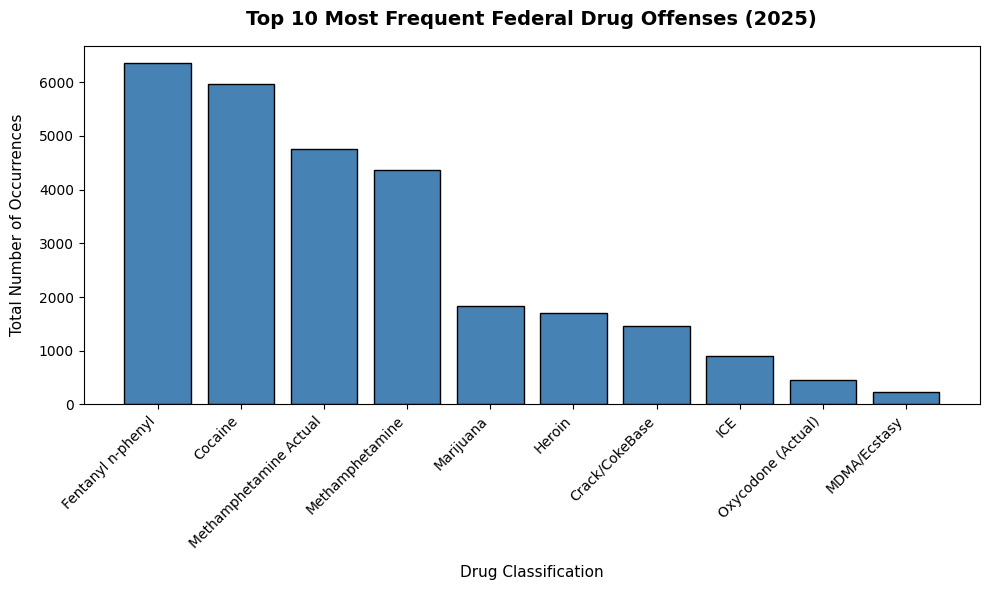

In [28]:
df_top_10 = final_leaderboard.sort_values(
    by="Total_Occurrences", ascending=False
).head(10)

#X (names) and Y (counts) variables
drug_names = df_top_10["Drug_Name"]
occurrences = df_top_10["Total_Occurrences"]

plt.figure(figsize=(10, 6))

plt.bar(drug_names, occurrences, color="steelblue", edgecolor="black")

plt.title(
    "Top 10 Most Frequent Federal Drug Offenses (2025)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Total Number of Occurrences", fontsize=11, labelpad=10)
plt.xlabel("Drug Classification", fontsize=11, labelpad=10)

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()